In [2]:
%load_ext autoreload
%autoreload 2
import os
os.chdir('/workspace/RL4Auditing')
import numpy as np
import matplotlib.pyplot as plt


In [12]:
from toy.create_toy import main

creating dataset
0 images are created
1000 images are created
2000 images are created
3000 images are created
4000 images are created
5000 images are created
6000 images are created
7000 images are created
8000 images are created
9000 images are created
10000 images are created
11000 images are created
12000 images are created
13000 images are created
14000 images are created
15000 images are created
16000 images are created
17000 images are created
18000 images are created
19000 images are created
20000 images are created
21000 images are created
22000 images are created
23000 images are created
24000 images are created
25000 images are created
26000 images are created
27000 images are created
28000 images are created
29000 images are created
30000 images are created
31000 images are created
32000 images are created
33000 images are created
34000 images are created
35000 images are created
36000 images are created
37000 images are created
38000 images are created
39000 images are crea

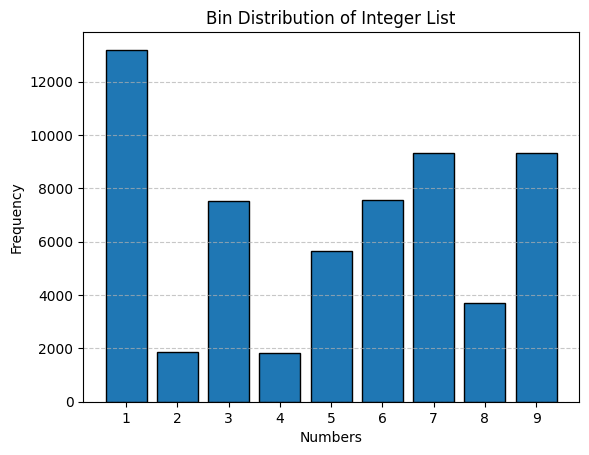

loading dataset


FileNotFoundError: [Errno 2] No such file or directory: 'concept_data.npy'

In [13]:
main()

(60000, 15)


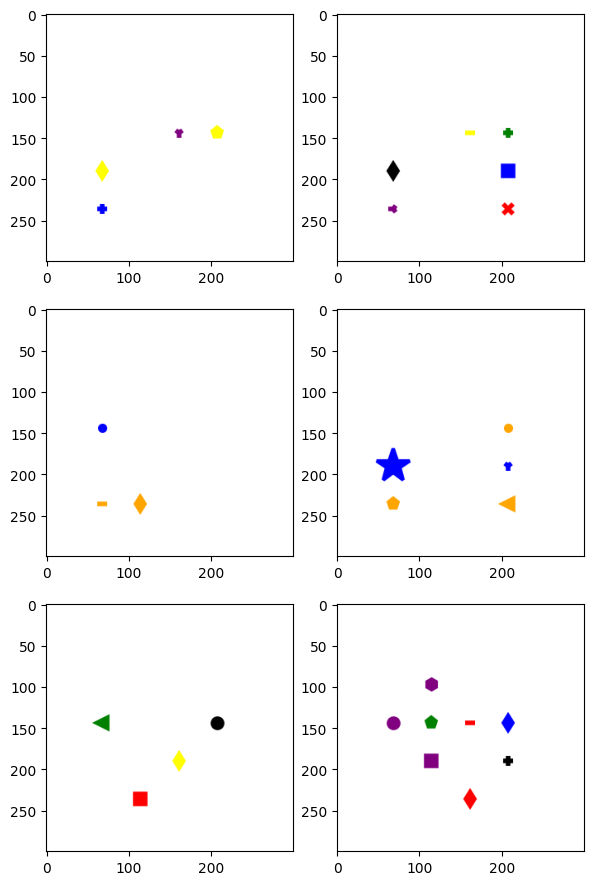

In [52]:
# import the dataset
import matplotlib.image as mpimg
import random

rand_list = []
for i in range(6):
    n=random.randint(100,200)
    rand_list.append(n)

x_data = np.load('../vu2/RL4Auditing/x_data.npy')
y_data = np.load('../vu2/RL4Auditing/y_data.npy')
concept_data = np.load('../vu2/RL4Auditing/concept_data.npy')
print(concept_data.shape)

rgb_grid = []

# Assign colors to each cell
for i in range(6):
    rgb_grid.append(x_data[rand_list[i],:])  # Vary red and green, keep blue constant

# Create a figure and set the grid size (2 rows, 5 columns)

fig, axes = plt.subplots(3, 2, figsize=(6, 9))  # Adjust figure size as needed

# Flatten the axes array to easily index it
axes = axes.ravel()

# Loop through images and axes to display
for i, img_path in enumerate(rgb_grid):
#     image = mpimg.imread(img_path)  # Load the image
    axes[i].imshow(img_path)           # Display the image
    axes[i].axis('on')             # Turn off axes for clean display
#     axes[i].set_title(f'Class %s'%(y_data[rand_list[i]]))
#     axes[i].set_title(f'Concept %s'%(concept_data[rand_list[i]]))

plt.tight_layout()  # Adjust layout for better spacing
# plt.show()
plt.savefig('../vu2/RL4Auditing/split_data/examples.pdf', dpi=600)

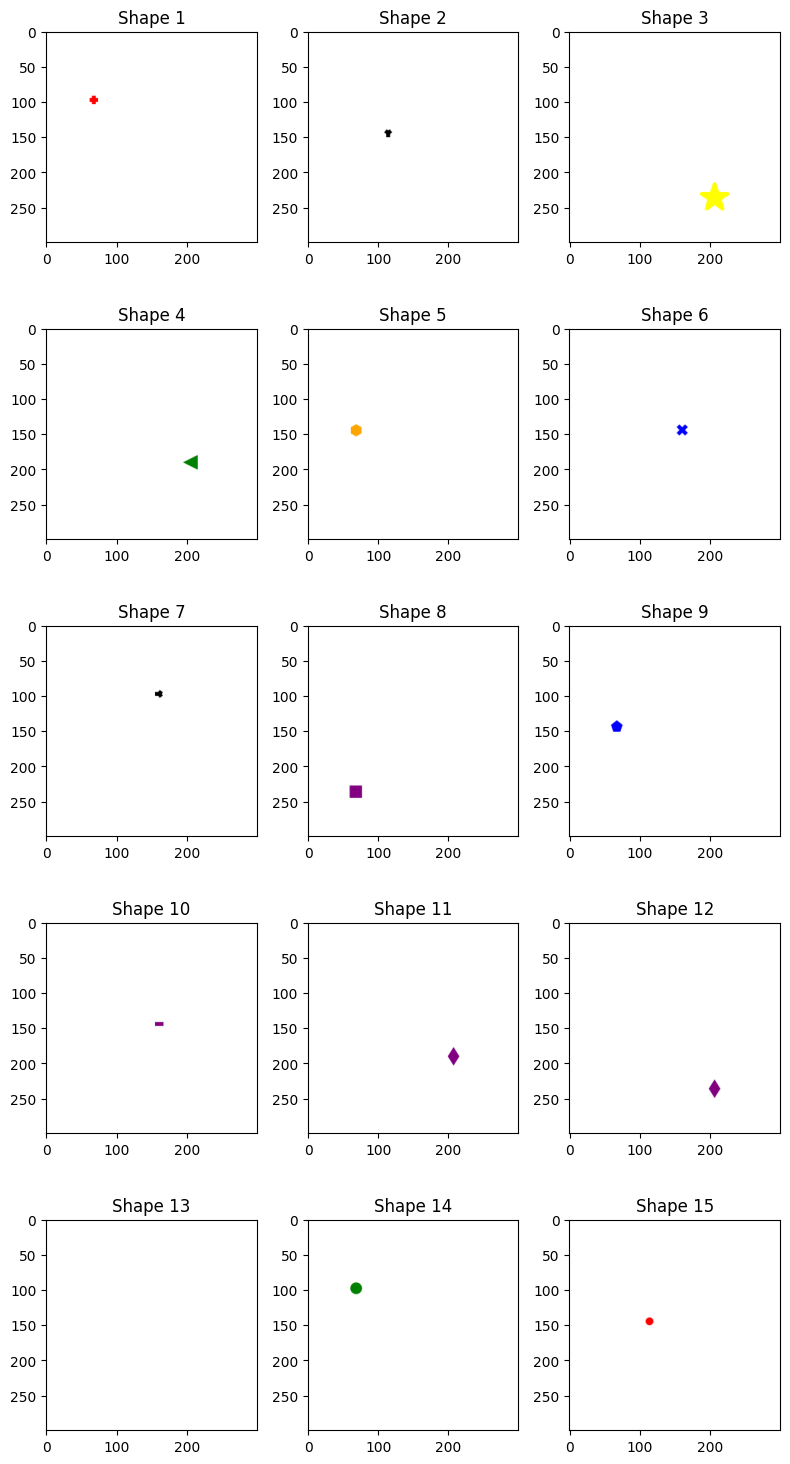

In [48]:
concept_grid = []

# Assign colors to each cell
for i in range(15):
    concept_grid.append(x_data[i,:])  # Vary red and green, keep blue constant

fig, axes = plt.subplots(5, 3, figsize=(8, 15))  # Adjust figure size as needed

# Flatten the axes array to easily index it
axes = axes.ravel()

# Loop through images and axes to display
for i, img_path in enumerate(concept_grid):
#     image = mpimg.imread(img_path)  # Load the image
    axes[i].imshow(img_path)           # Display the image
    axes[i].axis('on')             # Turn off axes for clean display
    axes[i].set_title(f'Shape %s'%(i+1))

plt.tight_layout()  # Adjust layout for better spacing
# plt.show()
plt.savefig('../vu2/RL4Auditing/split_data/shapes.pdf', dpi=600)

In [ ]:
print(x_data.shape)

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
import numpy as np

# Custom CNN Model
class CNN5Layer(nn.Module):
    def __init__(self, num_classes=15):
        super(CNN5Layer, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)  # Layer 1
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)  # Layer 2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)  # Layer 3
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)  # Layer 4
        self.conv5 = nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1)  # Layer 5
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # Downsampling
        self.relu = nn.ReLU()  # Activation function
        
        self.fc = nn.Linear(512 * 7 * 7, num_classes)  # Fully Connected Layer
        self.dropout = nn.Dropout(0.5)

    def forward(self, x, return_embedding=False):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.pool(self.relu(self.conv4(x)))
        x = self.pool(self.relu(self.conv5(x)))
        
        embeddings = x.view(x.size(0), -1)
        x = self.dropout(embeddings)
        x = self.fc(x)  # No activation (BCEWithLogitsLoss expects raw logits)
        if return_embedding:
            return x, embeddings
        return x


# Custom Dataset Class
class NPZImageDataset(torch.utils.data.Dataset):
    def __init__(self, npz_path, transform=None):
        data = np.load(npz_path)
        self.images = data['x'][:2000]
        self.labels = data['y'][:2000]  # Multi-labels as a numpy array
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = torch.tensor(self.images[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)  # Use float for CE loss
        
        if len(image.shape) == 2:  # Grayscale to 3 channels
            image = image.unsqueeze(0).repeat(3, 1, 1)
        else:
            image = image.permute(2, 0, 1)  # (H, W, C) -> (C, H, W)

        if self.transform:
            image = self.transform(image)
        return image, label
## Viz expl

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
import numpy as np

# Custom CNN Model
class CNN5Layer(nn.Module):
    def __init__(self, num_classes=15):
        super(CNN5Layer, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)  # Layer 1
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)  # Layer 2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)  # Layer 3
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)  # Layer 4
        self.conv5 = nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1)  # Layer 5
        
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)  # Downsampling
        self.relu = nn.ReLU()  # Activation function
        
        self.fc = nn.Linear(512 * 7 * 7, num_classes)  # Fully Connected Layer
        self.dropout = nn.Dropout(0.5)

    def forward(self, x, return_embedding=False):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = self.pool(self.relu(self.conv4(x)))
        x = self.pool(self.relu(self.conv5(x)))
        
        embeddings = x.view(x.size(0), -1)
        x = self.dropout(embeddings)
        x = self.fc(x)  # No activation (BCEWithLogitsLoss expects raw logits)
        if return_embedding:
            return x, embeddings
        return x


# Custom Dataset Class
class NPZImageDataset(torch.utils.data.Dataset):
    def __init__(self, npz_path, transform=None):
        data = np.load(npz_path)
        self.images = data['x'][:2000]
        self.labels = data['y'][:2000]  # Multi-labels as a numpy array
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = torch.tensor(self.images[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)  # Use float for CE loss
        
        if len(image.shape) == 2:  # Grayscale to 3 channels
            image = image.unsqueeze(0).repeat(3, 1, 1)
        else:
            image = image.permute(2, 0, 1)  # (H, W, C) -> (C, H, W)

        if self.transform:
            image = self.transform(image)
        return image, label


In [8]:
# load data
import pickle

VAL_NPZ = "../vu2/RL4Auditing/split_data/new2/val.npz"
TEST_NPZ = "../vu2/RL4Auditing/split_data/new2/test.npz"


transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Data Loaders
# train_dataset = NPZImageDataset(TRAIN_NPZ, transform=transform)
val_dataset = NPZImageDataset(VAL_NPZ, transform=transform)
test_dataset = NPZImageDataset(TEST_NPZ, transform=transform)

# train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

test_expl = np.load("../vu2/RL4Auditing/split_data/new2/test_expls.npy", allow_pickle=True).item()
val_expl = np.load("../vu2/RL4Auditing/split_data/new2/val_expls.npy", allow_pickle=True).item()

with open("../vu2/RL4Auditing/split_data/new2/val_position.pkl", 'rb') as file:
     val_location = pickle.load(file)
with open("../vu2/RL4Auditing/split_data/new2/test_position.pkl", 'rb') as file:  # Open the file in binary read mode
     test_location = pickle.load(file)

In [12]:
def evaluate_model_accuracy(model, dataloader):
    """
    Evaluate the accuracy of a model on a given dataloader.

    Args:
        model (torch.nn.Module): The PyTorch model to evaluate.
        dataloader (torch.utils.data.DataLoader): Dataloader with the evaluation dataset.
        device (torch.device): The device to perform the evaluation on (CPU or GPU).

    Returns:
        float: The accuracy of the model as a percentage.
    """
    model.eval()  # Set the model to evaluation mode
    correct = 0
    total = 0
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    with torch.no_grad():  # Disable gradient computation for evaluation
        for inputs, targets in dataloader:
            # Move inputs and targets to the specified device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass to get predictions
            outputs = model(inputs)

            # Get predicted class (index of the maximum logit)
            _, predicted = torch.max(outputs, dim=1)

            # Update total and correct counts
            total += targets.size(0)
            correct += (predicted == targets).sum().item()

    # Calculate accuracy
    accuracy = (correct / total) * 100
    return accuracy

In [13]:
# Load the trained model
model = CNN5Layer(num_classes=10)
model.load_state_dict(torch.load("../vu2/RL4Auditing/split_data/new2/cnn5layer_multi_label.pth"))

# Evaluate accuracy
accuracy = evaluate_model_accuracy(model, val_loader)
print(f"Model Accuracy Val: {accuracy:.2f}%")

# Evaluate accuracy
accuracy = evaluate_model_accuracy(model, test_loader)
print(f"Model Accuracy Test: {accuracy:.2f}%")
# # Evaluate per-class accuracy
# per_class_accuracy = evaluate_per_class_accuracy(model, val_loader, num_classes=15)

# per_class_accuracy = evaluate_per_class_accuracy(model, test_loader, num_classes=15)

Model Accuracy Val: 82.30%
Model Accuracy Test: 81.30%


In [29]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

def overlay_gradcam(image_tensor, gradcam_tensor, alpha=0.4, save_path=None):
    """
    Overlays a Grad-CAM heatmap onto an image.
    
    Parameters:
    - image_tensor (torch.Tensor): The input image tensor (C, H, W) or (1, C, H, W)
    - gradcam_tensor (torch.Tensor): The Grad-CAM heatmap tensor (H', W')
    - alpha (float): Opacity of the heatmap overlay
    """
    # Convert image tensor to numpy array
    if image_tensor.dim() == 4:  # If batch dimension exists
        image_tensor = image_tensor.squeeze(0)  # Remove batch dimension
    
    image = image_tensor.permute(1, 2, 0).cpu().numpy()  # Convert to (H, W, C)
    image = (image - image.min()) / (image.max() - image.min())  # Normalize
    image = (image * 255).astype(np.uint8)
    
    # Convert Grad-CAM tensor to numpy array
    gradcam = gradcam_tensor
    gradcam = cv2.resize(gradcam, (image.shape[1], image.shape[0]))  # Resize to match image
    gradcam = (gradcam - gradcam.min()) / (gradcam.max() - gradcam.min())  # Normalize
    gradcam = (gradcam * 255).astype(np.uint8)
    
    # Apply colormap to Grad-CAM
    heatmap = cv2.applyColorMap(gradcam, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
    
    # Overlay heatmap onto image
    overlay = cv2.addWeighted(image, 1 - alpha, heatmap, alpha, 0)
    if save_path:
        cv2.imwrite(save_path, cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
        
    # Display the result
    plt.figure(figsize=(8, 8))
    plt.imshow(overlay)
    plt.axis('off')
    plt.show()
    
    return overlay



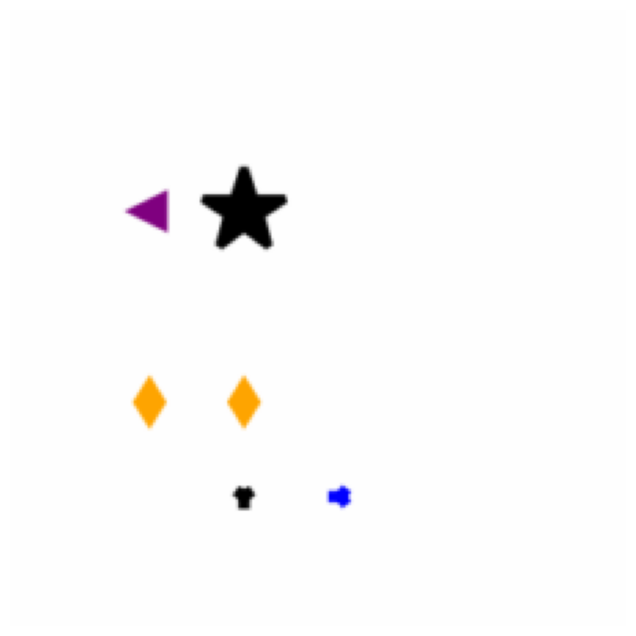

array([[[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       ...,

       [[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]],

       [[254, 254, 254],
        [254, 254, 254],
        [254, 254, 254],
        ...,
        [254, 254, 254],
        [254, 254, 254],
        [254, 254, 254]]

In [31]:
img = val_dataset[1][0]
expl = val_expl[1]

overlay_gradcam(img, expl, alpha=0.0, save_path="../vu2/RL4Auditing/split_data/new5/original.png")